# 🎧 MoodTune NLP — Documentation du pipeline
**Projet NLP — Analyse sémantique et recommandation contextuelle (Thème 4 : musique selon l'humeur)**
Groupe 2 : Kelly Abendjock, Magaret Ngwanya, Axel Remillat, Lucas San Frutos — ESME 2026-2027

Ce notebook documente pas à pas le moteur utilisé par l'application Streamlit (`app.py`) :
1. le jeu de données de référence ;
2. le prétraitement ;
3. les embeddings SBERT et la similarité cosinus ;
4. la transformation des échelles de Likert en texte ;
5. le score global pondéré et le Top 3 ;
6. la comparaison avec une approche par mots-clés (TF-IDF) ;
7. la carte sémantique 2D.

In [1]:
import pandas as pd, numpy as np
from src.nlp_engine import MusicSemanticEngine, genre_family
pd.set_option("display.max_colwidth", 80)

## 1. Jeu de données de référence
75 morceaux, chacun décrit uniquement par du texte. Les 71 genres sont regroupés en 8 familles pour les graphiques.

In [2]:
df = pd.read_csv("data/tracks_dataset.csv")
df["Famille"] = df["Genre"].apply(genre_family)
print(df.shape)
df[["Title", "Genre", "Mood", "Context"]].head()

(75, 9)


,Title,Genre,Mood,Context
0,Midnight Study Session,Lo-Fi Hip Hop,"Calme, apaisant, mélancolique doux, nostalgique","Travail, étude, lecture tardive, concentration profonde"
1,Weightless Horizons,Ambient,"Sérénité absolue, méditatif, flottant, anti-stress","Méditation, relaxation, sommeil, gestion du stress"
2,River Flows in Silence,Néo-Classique,"Poétique, doux, introspectif, émouvant","Lecture, écriture, travail créatif, moment calme"
3,Coffee & Raindrops,Chillhop,"Chaleureux, cosy, détendu, réconfortant","Télétravail, café, révisions, matin tranquille"
4,Deep Focus Architecture,Ambient,"Neutre, immersif, minimaliste, stable","Programmation, analyse de données, révisions intensives"


In [3]:
df["Famille"].value_counts()

Famille
Calme / Instrumental    20
Électro / Dance         17
Jazz / Soul / Funk      12
Rock / Metal             7
Musiques du monde        7
Pop / Folk / Chanson     6
Rap / Hip-Hop            3
Orchestral / Cinéma      3
Name: count, dtype: int64

**Lecture :** le catalogue couvre des ambiances très variées (calme, électro, jazz, rock…). La famille « Calme / Instrumental » est la plus représentée, ce qui colle aux usages étude / détente.

## 2. Prétraitement
Volontairement **léger** : on retire seulement les espaces en trop. Pas de suppression de stopwords ni de lemmatisation, car SBERT est entraîné sur des phrases complètes : « **pas** de paroles » et « paroles » n'ont pas le même sens, et supprimer « pas » casserait l'information.

In [4]:
MusicSemanticEngine.preprocess_text("   Je  veux   de la musique    SANS paroles  ")

'Je veux de la musique SANS paroles'

## 3. Embeddings SBERT et similarité cosinus
Modèle : `paraphrase-multilingual-MiniLM-L12-v2` (multilingue, vecteurs de 384 dimensions).

In [5]:
engine = MusicSemanticEngine("data/tracks_dataset.csv")
v = engine.model.encode("réviser au calme la nuit")
print("Dimension d'un embedding :", v.shape)

Dimension d'un embedding : (384,)


In [6]:
from sentence_transformers import util
requete = "réviser au calme la nuit"
phrases = ["concentration profonde, atmosphère nocturne apaisante",
           "study music for late night focus",
           "musique explosive pour faire la fête",
           "rock énergique avec guitares saturées"]
emb_q = engine.model.encode(requete, normalize_embeddings=True)
emb_p = engine.model.encode(phrases, normalize_embeddings=True)
pd.DataFrame({"phrase": phrases, "similarité cosinus": util.cos_sim(emb_q, emb_p)[0].numpy().round(3)})

,phrase,similarité cosinus
0,"concentration profonde, atmosphère nocturne apaisante",0.660
1,study music for late night focus,0.595
2,musique explosive pour faire la fête,0.409
3,rock énergique avec guitares saturées,0.271


**Lecture :** les deux premières phrases n'ont presque aucun mot en commun avec la requête (la 2ᵉ est même en anglais), pourtant ce sont elles qui ressortent. C'est tout l'intérêt d'un modèle sémantique multilingue par rapport à une recherche par mots-clés.

## 4. Échelles de Likert → texte
Un chiffre (« énergie 2/5 ») ne veut rien dire pour un modèle de langage. On le traduit donc en mots avant l'encodage :

| Énergie | Texte ajouté à la requête |
|---|---|
| 1 | très calme, lent, apaisant, doux |
| 2 | calme, posé, tranquille |
| 3 | énergie modérée, équilibrée |
| 4 | dynamique, rythmé, entraînant |
| 5 | très énergique, intense, puissant, rapide |

Même principe pour l'importance des paroles (1 = strictement instrumental … 5 = paroles essentielles).

## 5. Score global pondéré et Top 3
Chaque morceau est comparé sur 3 blocs : **humeur** (Mood + Description), **contexte** (Context + Keywords) et **genre** (Genre + Keywords).

$$Score_{global} = \frac{W_{mood} S_{mood} + W_{context} S_{context} + W_{genre} S_{genre}}{W_{mood} + W_{context} + W_{genre}}$$

Poids par défaut : 0,5 / 0,3 / 0,2 (l'humeur est l'information principale du questionnaire). Ils sont modifiables dans l'application.

In [7]:
scenarios = {
  "A - Révisions calmes": dict(mood_text="Je recherche une musique instrumentale relaxante qui m'aide à me concentrer pendant mes études, avec une atmosphère calme et apaisante.",
      style_text="Du piano doux ou des sonorités lo-fi feutrées, sans paroles distrayantes.",
      contexts=["Travail / Étude / Concentration"], genres=["Lo-Fi Hip Hop", "Ambient"], energy_likert=2, vocals_likert=1),
  "B - Séance de sport": dict(mood_text="J'ai besoin d'une musique puissante et motivante pour me pousser à fond à la salle de sport",
      style_text="grosses basses, rythme rapide", contexts=["Sport / Running / Musculation"],
      genres=["Trap / Rap", "Electro / EDM"], energy_likert=5, vocals_likert=4),
  "C - Soirée pluvieuse": dict(mood_text="Il pleut, je me sens un peu mélancolique et nostalgique ce soir",
      style_text="guitare acoustique, voix douce", contexts=["Introspection / Pluie / Solitude"],
      genres=["Indie Folk"], energy_likert=1, vocals_likert=4),
}
cols = ["Title", "Genre", "Score_Global", "Score_Mood", "Score_Context", "Score_Genre"]
for nom, profil in scenarios.items():
    res, _, _ = engine.recommend(profil)
    print("\n===", nom, "===")
    print(res[cols].head(3).to_string(index=False))


=== A - Révisions calmes ===
                 Title         Genre  Score_Global  Score_Mood  Score_Context  Score_Genre
Midnight Study Session Lo-Fi Hip Hop          75.4        75.8           67.5         86.3
    Dawn over the Alps Néo-Classique          69.9        74.3           65.6         65.2
River Flows in Silence Néo-Classique          68.8        70.7           68.2         64.9

=== B - Séance de sport ===
              Title                 Genre  Score_Global  Score_Mood  Score_Context  Score_Genre
   Break the Chains      Metal / Nu-Metal          60.3        69.6           54.9         45.1
Unstoppable Mindset         Hip-Hop / Rap          59.1        59.9           61.6         53.2
       New Horizons Orchestral Soundtrack          57.8        58.8           55.7         58.3



=== C - Soirée pluvieuse ===
             Title            Genre  Score_Global  Score_Mood  Score_Context  Score_Genre
      Wooden Cabin    Acoustic Folk          73.7        76.1           59.2         89.3
Coffee & Raindrops         Chillhop          69.4        78.7           57.4         64.1
 Creep in the Dark Alternative Rock          68.6        71.1           69.1         61.7


**Lecture :** chaque scénario renvoie des morceaux cohérents : lo-fi et néo-classique pour les révisions, metal / rap / orchestral épique pour le sport, folk acoustique et chillhop pour la soirée pluvieuse. On remarque que le genre coché n'est pas imposé : en B, un morceau de metal passe devant le rap, parce que son **humeur** (puissance, motivation) colle mieux au texte libre, qui pèse 50 %.

## 6. Comparaison avec une approche par mots-clés (TF-IDF)
Pour justifier SBERT, on refait le classement du scénario A avec un simple TF-IDF + cosinus sur la description complète des morceaux.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
corpus = (df["Genre"] + " " + df["Mood"] + " " + df["Context"] + " " + df["Description"] + " " + df["Keywords"]).tolist()
tfidf = TfidfVectorizer()
X = tfidf.fit_transform(corpus)

def compare(requete):
    sims = cosine_similarity(tfidf.transform([requete]), X)[0]
    top = df.assign(TFIDF=sims.round(3)).sort_values("TFIDF", ascending=False).head(3)
    res, _, _ = engine.recommend(dict(mood_text=requete, style_text="", contexts=[], genres=[], energy_likert=3, vocals_likert=3))
    print("Requête :", requete)
    print("  TF-IDF :", list(zip(top["Title"], top["Genre"], top["TFIDF"])))
    print("  SBERT  :", list(zip(res["Title"].head(3), res["Genre"].head(3), res["Score_Global"].head(3))))

compare("je dois bosser tard le soir sans être dérangé")
compare("I need hype music to lift heavy at the gym")

Requête : je dois bosser tard le soir sans être dérangé
  TF-IDF : [('Bittersweet Youth', 'Indie Pop', 0.133), ('Weightless Horizons', 'Ambient', 0.122), ('Sunset Boulevard', 'Chillout', 0.116)]
  SBERT  : [('Midnight Study Session', 'Lo-Fi Hip Hop', 51.2), ('Coffee & Raindrops', 'Chillhop', 50.4), ('Dawn over the Alps', 'Néo-Classique', 48.8)]


Requête : I need hype music to lift heavy at the gym
  TF-IDF : [('Midnight Study Session', 'Lo-Fi Hip Hop', 0.0), ('Weightless Horizons', 'Ambient', 0.0), ('River Flows in Silence', 'Néo-Classique', 0.0)]
  SBERT  : [('Break the Chains', 'Metal / Nu-Metal', 54.7), ('Winter Sonata', 'Cello Solo', 53.3), ('Dawn over the Alps', 'Néo-Classique', 52.8)]


**Lecture :**
- Requête 1 (paraphrase, aucun mot du catalogue) : TF-IDF remonte de l'indie pop avec des scores autour de 0,1, donc presque au hasard. SBERT comprend « bosser tard » ≈ « étude, concentration, nuit » et propose du lo-fi et du chillhop.
- Requête 2 (en anglais) : TF-IDF obtient **0 partout**, il ne trouve aucun mot commun. SBERT, multilingue, place le morceau de metal en tête.
- SBERT n'est pas parfait : sur la requête 2, un solo de violoncelle arrive 2ᵉ. Sans questionnaire complet (contexte, genres, énergie), le texte seul ne suffit pas toujours, d'où l'intérêt des 3 blocs pondérés.

## 7. Carte sémantique 2D (PCA)
Les embeddings de 384 dimensions sont projetés en 2D : deux points proches = deux morceaux au sens proche. L'étoile rouge est la requête du scénario A.

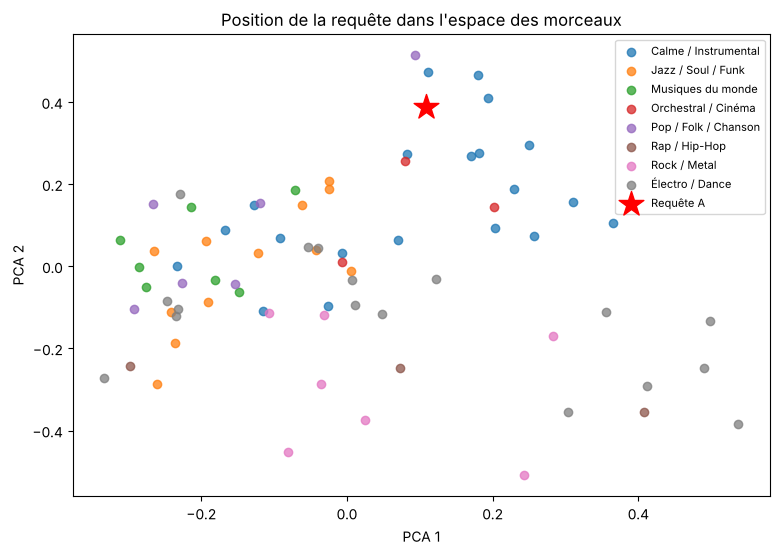

In [9]:
import matplotlib.pyplot as plt
res, coords, user = engine.recommend(scenarios["A - Révisions calmes"])
fig, ax = plt.subplots(figsize=(9, 6))
for fam, g in df.groupby("Famille"):
    ax.scatter(coords[g.index, 0], coords[g.index, 1], label=fam, alpha=.75)
ax.scatter(*user, marker="*", s=350, c="red", label="Requête A")
ax.set_xlabel("PCA 1"); ax.set_ylabel("PCA 2"); ax.legend(fontsize=8)
ax.set_title("Position de la requête dans l'espace des morceaux")
plt.show()

**Lecture :** les familles forment des zones (calme d'un côté, électro / rock de l'autre) alors que le modèle n'a jamais vu de label de famille : la structure vient uniquement du texte. La requête « révisions calmes » tombe bien dans la zone des morceaux calmes.

## 8. Limites et pistes
- Catalogue de 75 morceaux rédigé à la main : les descriptions restent subjectives.
- Aucune analyse audio, seulement du texte.
- Les scores cosinus sont resserrés (≈ 20 à 80 %), c'est surtout le **classement** qui compte.
- Pistes : connecter l'API Spotify pour un vrai catalogue, ajouter un retour utilisateur (« j'aime / j'aime pas ») pour ajuster les poids, tester un modèle plus gros (`multilingual-mpnet`).